# Telco Customer Churn EDA

# 1. Business Understanding
## 1.1 Problem Statement
The company is experiencing a high rate of customer churn, leading to revenue loss.
We aim to identify customers at risk of churn and understand the main drivers behind it.

## 1.2. Objectives
- Understand the distribution of churn across customer segments
- Identify features strongly associated with churn
- Build a classification model to predict churn probability

## 1.3. Success Metrics (Business + Technical)
- Business
  - Reduce chrun by 10%
  - Increase revenue by $6k-$10k/month
- Model
  - Recall ≥ 0.75
  - Precision ≥ 0.60
  - ROC-AUc ≥ 0.80
  - Lift ≥ 2x in top 20%
- Analytical
  - Identify top 3-5 churn drivers
  - Produce actionable segments

## 1.4. Assumptions & Constraints



# 2. Dataset Overview

## 2.1. Dataset Description
The dataset contains 7,043 customer records and 33 features.
It includes demographic, service usage, and billing information.
The target variable is "Churn Value", indicating whether a customer left the company.

## 2.2. Data Sources
The dataset was obtained from IBM Sample Data (Telco Customer Churn dataset).
It represents customer behavior in a telecommunications company.

## 2.3. Data Dictionary
The data dictionary below describes each variable, including its data type, possible values, and business meaning.

7043 observations with 33 variables

| Variable          | Data Type      | Allowed Values / Domain                    | Description                               |
| ----------------- | -------------- | ------------------------------------------ | ----------------------------------------- |
| CustomerID        | str            | Unique identifier                          | A unique ID that identifies each customer |
| Count             | int64          | Constant (e.g., 1)                         | Used for aggregation/counting in reports  |
| Country           | str            | Categorical (e.g., USA, Brazil)            | Customer’s country of residence           |
| State             | str            | Categorical                                | Customer’s state                          |
| City              | str            | Categorical                                | Customer’s city                           |
| Zip Code          | int64          | Postal codes                               | Customer’s ZIP/postal code                |
| Lat Long          | str            | "lat, long" format                         | Combined latitude and longitude           |
| Latitude          | float64        | [-90, 90]                                  | Geographic latitude                       |
| Longitude         | float64        | [-180, 180]                                | Geographic longitude                      |
| Gender            | str            | Male, Female                               | Customer gender                           |
| Senior Citizen    | str            | Yes, No                                    | Whether customer is ≥ 65 years old        |
| Partner           | str            | Yes, No                                    | Whether customer has a partner            |
| Dependents        | str            | Yes, No                                    | Whether customer has dependents           |
| Tenure Months     | int64          | ≥ 0                                        | Number of months as a customer            |
| Phone Service     | str            | Yes, No                                    | Subscription to phone service             |
| Multiple Lines    | str            | Yes, No                                    | Multiple phone lines subscription         |
| Internet Service  | str            | No, DSL, Fiber Optic, Cable                | Type of internet service                  |
| Online Security   | str            | Yes, No                                    | Additional online security service        |
| Online Backup     | str            | Yes, No                                    | Additional backup service                 |
| Device Protection | str            | Yes, No                                    | Device protection plan                    |
| Tech Support      | str            | Yes, No                                    | Technical support subscription            |
| Streaming TV      | str            | Yes, No                                    | Uses internet for TV streaming            |
| Streaming Movies  | str            | Yes, No                                    | Uses internet for movie streaming         |
| Contract          | str            | Month-to-Month, One Year, Two Year         | Customer contract type                    |
| Paperless Billing | str            | Yes, No                                    | Uses paperless billing                    |
| Payment Method    | str            | Bank Withdrawal, Credit Card, Mailed Check | Payment type                              |
| Monthly Charges   | float64        | ≥ 0                                        | Monthly cost                              |
| Total Charges     | object⚠️       | Numeric (should be float)                  | Total accumulated charges                 |
| Churn Label       | str            | Yes, No                                    | Churn status (label)                      |
| Churn Value       | int64          | 0, 1                                       | Binary churn indicator                    |
| Churn Score       | int64          | [0–100]                                    | Model-based churn probability score       |
| CLTV              | int64          | ≥ 0                                        | Customer lifetime value                   |
| Churn Reason      | str (nullable) | Multiple categories                        | Reason for churn                          |

# 3. Environmnet Setup

## 3.1. Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport

/tmp/ipykernel_967/1978443558.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 3.2 Configuration & Display Settings

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

## 3.3. Load Dataset

In [21]:
df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")
df.head(10)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices
5,4190-MFLUW,1,United States,California,Los Angeles,90020,"34.066367, -118.309868",34.066367,-118.309868,Female,No,Yes,No,10,Yes,No,DSL,No,No,Yes,Yes,No,No,Month-to-month,No,Credit card (automatic),55.20,528.35,Yes,1,78,5925,Competitor offered higher download speeds
6,8779-QRDMV,1,United States,California,Los Angeles,90022,"34.02381, -118.156582",34.023810,-118.156582,Male,Yes,No,No,1,No,No phone service,DSL,No,No,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,Yes,1,100,5433,Competitor offered more data
7,1066-JKSGK,1,United States,California,Los Angeles,90024,"34.066303, -118.435479",34.066303,-118.435479,Male,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes,1,92,4832,Competitor made better offer
8,6467-CHFZW,1,United States,California,Los Angeles,90028,"34.099869, -118.326843",34.099869,-118.326843,Male,No,Yes,Yes,47,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.35,4749.15,Yes,1,77,5789,Competitor had better devices
9,8665-UTDHZ,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,No,Electronic check,30.20,30.2,Yes,1,97,2915,Competitor had better devices


# 4. Data Quality Assessment (Sanity Check)

## 4.1 Dataset Shape and Structure

/tmp/ipykernel_967/4040952179.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


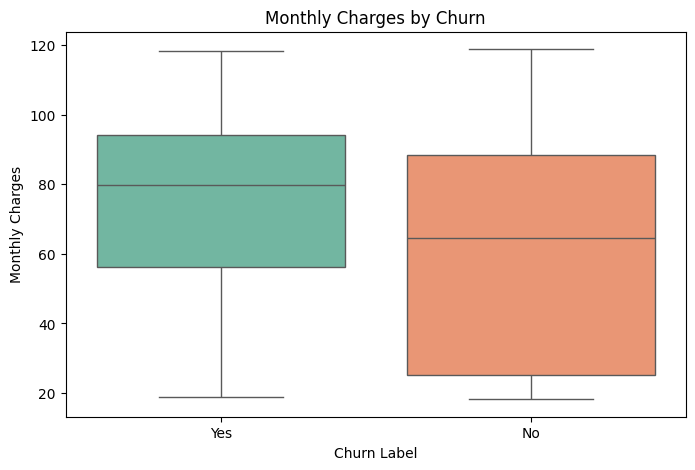

In [30]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Monthly Charges",
    palette="Set2"
)

plt.title("Monthly Charges by Churn")
plt.show()

In [ ]:
df.shape

In [37]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Tenure Months    7043 non-null   int64  
 1   Monthly Charges  7043 non-null   float64
 2   Total Charges    7032 non-null   float64
 3   CLTV             7043 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 220.2 KB


In [35]:
df_new = df[['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']]
df_new.describe()

,Tenure Months,Monthly Charges,Total Charges,CLTV
count,7043.000000,7043.000000,7032.000000,7043.000000
mean,32.371149,64.761692,2283.300441,4400.295755
std,24.559481,30.090047,2266.771362,1183.057152
min,0.000000,18.250000,18.800000,2003.000000
25%,9.000000,35.500000,401.450000,3469.000000
50%,29.000000,70.350000,1397.475000,4527.000000
75%,55.000000,89.850000,3794.737500,5380.500000
max,72.000000,118.750000,8684.800000,6500.000000


### Analysis
- The dataset contains **7043 rows and 33 columns**, which is sufficient for a baseline ML model.
- No immediate concerns regarding dataset size for classical models.
- Presence of both **categorical and numerical features** suggests the need for encoding and scaling.
- `Total Charges` → likely due to incorrect data type (object instead of float)

**Impact:**
- Dataset is suitable for supervised learning.
- Mixed data types require preprocessing pipeline.
- `Total Charges` requires cleaning before modeling.

**Action:**
- Proceed with feature type separation (categorical vs numerical).
- Convert `Total Charges` to float and handle missing values.

## 4.2 Missing Values Analysis

In [ ]:
df.isnull().sum()

### Analysis

- Missing values detected in:
  - `Churn Reason` → expected, as it only exists for churned customers

- Missingness in `Churn Reason` is **not a data quality issue**, but a **business logic artifact**.

**Impact:**
- `Churn Reason` must be excluded from training to avoid leakage.

**Action:**
- Drop `Churn Reason` from feature set.

## 4.3 Inconsistent / Invalid Values

In [ ]:

df.describe()

In [ ]:
for column in df.select_dtypes(include=['object', 'category']).columns:
    print(f"\nColumn: {column}")
    print(df[column].unique())
    # print(f"Unique values ({df[column].nunique()}):")
    # print(df[column].value_counts())

### Analysis

Categorical value inspection reveals the following:

#### 1. Identifier Columns
- `CustomerID` has **7043 unique values** → confirms it is a unique identifier.
  
**Impact:**
- Not useful for modeling (no predictive power)

**Action:**
- Drop from feature set

---

#### 2. Low-Variance / Constant Columns
- `Country` = only "United States"
- `State` = only "California"

**Impact:**
- No variability → no predictive signal

**Action:**
- Drop both columns

---

#### 3. High Cardinality Columns
- `City` → 1129 unique values
- `Lat Long` → 1652 unique values

**Impact:**
- High cardinality may:
  - Increase model complexity
  - Lead to overfitting
  - Require heavy encoding (e.g., target encoding)

**Action:**
- Consider:
  - Dropping (`City`, `Lat Long`)
  - Or feature engineering (e.g., clustering, region grouping)

---

#### 4. Redundant Features
- `Lat Long` duplicates information from:
  - `Latitude`
  - `Longitude`

**Impact:**
- Redundant representation → unnecessary complexity

**Action:**
- Drop `Lat Long`, keep numerical coordinates

---

#### 5. Binary Categorical Consistency
Columns with consistent values:
- `Gender`, `Senior Citizen`, `Partner`, `Dependents`
- `Phone Service`, `Paperless Billing`, `Churn Label`

Values are standardized:
- "Yes"/"No", "Male"/"Female"

**Impact:**
- No inconsistency issues

**Action:**
- Encode as binary variables

---

#### 6. Multi-Class Categorical Variables
Columns like:
- `Contract`, `Payment Method`, `Internet Service`

Values are:
- Clean
- Well-defined
- No inconsistencies (e.g., no duplicates like "Month-to-month" vs "month-to-month")

**Impact:**
- Suitable for encoding

**Action:**
- Apply One-Hot Encoding or similar

---

#### 7. Domain Inconsistency in Service-Related Features ⚠️

Columns affected:
- `Multiple Lines`
- `Online Security`
- `Online Backup`
- `Device Protection`
- `Tech Support`
- `Streaming TV`
- `Streaming Movies`

Observed values:
- "Yes", "No"
- "No internet service"
- "No phone service"

**Expected domain:**
- Binary (Yes / No)

**Issue:**
- Mixing service availability with feature value

**Impact:**
- Violates domain definition
- Introduces ambiguity and noise
- Can bias model interpretation

**Action:**
- Normalize to binary:
  - "No internet service" → "No"
  - "No phone service" → "No"

---

#### 8. Granularity Mismatch in Payment Method ⚠️

Observed values:
- "Mailed check"
- "Electronic check"
- "Bank transfer (automatic)"
- "Credit card (automatic)"

Expected (dictionary):
- Bank Withdrawal
- Credit Card
- Mailed Check

**Issue:**
- Dataset is more granular than documentation

**Impact:**
- Inconsistency between data and dictionary
- Potential fragmentation in modeling

**Action (advanced):**
- Keep granular categories for better predictive performance

**Alternative (standardization):**

| Original Value                | Standardized Value |
|------------------------------|--------------------|
| Electronic check             | Bank Withdrawal    |
| Bank transfer (automatic)    | Bank Withdrawal    |
| Credit card (automatic)      | Credit Card        |
| Mailed check                 | Mailed Check       |

---

#### 9. Implicit Missing Values (Important ⚠️)

Service-related columns contain:
- "No internet service"
- "No phone service"

**Interpretation:**
- Represent conditional absence, not true categories

**Impact:**
- Can distort feature importance and relationships

**Action:**
- Treat as "No" OR engineer separate availability features

---

#### 10. Target Leakage Risk ⚠️

- `Churn Reason`:
  - Contains **21 categories + NaN**
  - Only available for churned customers

**Impact:**
- Direct leakage (post-event information)
- Would artificially inflate model performance

**Action:**
- Drop from training dataset
- Use only for post-hoc analysis

---

#### 11. Data Type Inconsistency

- `Total Charges`:
  - Appears numeric but previously detected as `object`

**Impact:**
- Indicates possible invalid values (e.g., blanks)
- Can break modeling pipeline

**Action:**
- Convert to numeric and validate missing values

---

### Summary of Issues

| Issue Type              | Columns Affected                  | Severity |
|------------------------|----------------------------------|----------|
| Constant Features      | Country, State                   | Low      |
| High Cardinality       | City, Lat Long                   | Medium   |
| Redundancy             | Lat Long                         | Low      |
| Domain Inconsistency   | Service-related columns          | Medium   |
| Category Granularity   | Payment Method                   | Medium   |
| Data Type Issue        | Total Charges                    | High     |
| Leakage Risk           | Churn Reason                     | Critical |

---

### Final Actions

- Drop: `CustomerID`, `Country`, `State`, `Lat Long`, `Churn Reason`
- Fix: `Total Charges` dtype
- Normalize: service-related categorical columns
- Standardize or evaluate: `Payment Method`
- Encode: categorical variables appropriately

## 4.4 Duplicate Records

In [ ]:
df.nunique()

In [ ]:
df.duplicated().sum()

### Analysis

- No duplicate records found based on `CustomerID`.
- Each row represents a unique customer.

**Impact:**
- No risk of bias due to duplicated samples.

**Action:**
- No action required.

## 4.5 Data Types Validation

In [ ]:
df.info()

In [ ]:
# Check if Total Charges is really numeric
df['Total Charges'].str.strip().replace('', None)

In [ ]:
# Attempt conversion and inspect failures
invalid_mask = pd.to_numeric(df['Total Charges'], errors='coerce').isna()
df.loc[invalid_mask, 'Total Charges'].head()

### Analysis
- Data types are mostly appropriate at the structural level.
- Key issue:
  - `Total Charges` is stored as **object**, but should be **float**.
  - Validation revealed **empty strings / whitespace values**, leading to invalid numeric entries.

- Categorical columns are correctly stored as strings and ready for encoding.

**Impact:**
- Invalid values in `Total Charges` prevent proper numeric conversion and may break aggregations and ML pipelines.

**Action:**
- Clean invalid entries (empty/whitespace values)
- Convert `Total Charges` to numeric
- Review resulting missing values before modeling

## 4.6 Outlier Detection

In [ ]:
target = 'Churn Value'
num_vars = [col for col in df.columns if df[col].dtype in ['int64', 'float64'] and col != target]
cat_vars = [col for col in df.columns if (df[col].dtype == 'object' or str(df[col].dtype) == 'category' or df[col].dtype == 'str') and col != target]

In [ ]:
# Boxplots for numerical variables

# Create subplots based on the number of numerical variables
fig, axes = plt.subplots(nrows=len(num_vars), ncols=1, figsize=(8, 4 * len(num_vars)))

# If there is only one variable, 'axes' is not a list — adjust it
if len(num_vars) == 1:
    axes = [axes]

# Iterate over numerical variables and plot each boxplot
for i, col in enumerate(num_vars):
    sns.boxplot(x=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Analysis

- `Monthly Charges` ranges from ~18 to ~118 → appears reasonable for telecom pricing.
- `Tenure Months` ranges from 0 to 72 → expected lifecycle.
- `CLTV` ranges from ~2000 to ~6500 → no extreme anomalies detected.

- No clear evidence of extreme outliers that would distort the model.

**Impact:**
- Outliers are not likely to significantly affect model performance.

**Action:**
- No aggressive outlier removal needed.
- Consider scaling numerical features if required by model.

## 4.7 Data Quality Summary

### Key Issues Identified
- `Total Charges` type inconsistency
- Presence of non-informative column (`Count`)
- Potential data leakage (`Churn Score`, `Churn Reason`)

### Risk Assessment
- Medium risk if not addressed before modeling

### Final Actions Before Modeling
- Data type correction
- Feature selection (remove leakage columns)
- Encoding strategy for categorical variables

In [ ]:
# drop unnecessary columns
df_dq_processing = df.drop(columns=['Country', 'State', 'Count', 'Lat Long', 'CustomerID', 'Zip Code'])

# transform 'Total Charges' to float
df_dq_processing['Total Charges'] = pd.to_numeric(df_dq_processing['Total Charges'], errors='coerce')

# transform column names
df_dq_processing.columns = (
    df_dq_processing.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^\w]+", "_", regex=True)
    .str.replace(r"__+", "_", regex=True)
    .str.strip("_")
)

In [ ]:
# save as a parquet
df_dq_processing.to_parquet("../data/interim/df_dq.parquet")

# 5 Exploratory Data Analysis (EDA)

## Create a Profile Report of DQ result

In [ ]:
df = pd.read_parquet("../data/interim/df_dq.parquet")

profile = ProfileReport(df, title="EDA Report", explorative=True)
profile.to_file("../reports/profiling/report_v1_dq.html")

## Balanced Dataset Creation

In [20]:
# load df
df = pd.read_parquet("../data/interim/df_dq.parquet")

# Separate Classes
df_0 = df[df['churn_value'] == 0]
df_1 = df[df['churn_value'] == 1]

# Determine minority class size
n = min(len(df_0), len(df_1))

# Undersample majority class
df_0_sampled = df_0.sample(n=n, random_state=42)
df_1_sampled = df_1.sample(n=n, random_state=42)

# Combine and shuffle
df_balanced = pd.concat([df_0_sampled, df_1_sampled]) \
                .sample(frac=1, random_state=42) \
                .reset_index(drop=True)


In [21]:
# Validate Result
df_balanced['churn_value'].value_counts()

churn_value
0    1869
1    1869
Name: count, dtype: int64

In [22]:
# Save new dataset
df_balanced.to_parquet("../data/processed/df_balanced.parquet", index=False)

## Report of balanced df

In [24]:
df = pd.read_parquet("../data/processed/df_balanced.parquet")

profile = ProfileReport(df, title="Balanced DF Report", explorative=True)
profile.to_file("../reports/profiling/report_v2_balanced.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 27/27 [00:00<00:00, 186567.06it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## Select columns with <0.3 correlation

In [27]:
# load df
df = pd.read_parquet("../data/processed/df_balanced.parquet")

# select relevant columns
columns = [
    "churn_reason",
    "contract",
    "dependents",
    "device_protection",
    "internet_service",
    "monthly_charges",
    "online_backup",
    "online_security",
    "payment_method",
    "tech_support",
    "tenure_months",
    "churn_value"
]

df_selected = df[columns]

df_selected.to_parquet("../data/interim/df_selected.parquet", index=False)

In [28]:

df = pd.read_parquet("../data/interim/df_selected.parquet")

display(df)

,churn_reason,contract,dependents,device_protection,internet_service,monthly_charges,online_backup,online_security,payment_method,tech_support,tenure_months,churn_value
0,None,Month-to-month,Yes,No,DSL,57.65,No,Yes,Mailed check,No,18,0
1,None,One year,No,Yes,DSL,68.75,No,Yes,Bank transfer (automatic),No,56,0
2,None,One year,No,No internet service,No,19.80,No internet service,No internet service,Mailed check,No internet service,15,0
3,None,One year,Yes,Yes,DSL,78.95,Yes,No,Credit card (automatic),No,38,0
4,None,Two year,No,Yes,DSL,89.30,Yes,Yes,Credit card (automatic),Yes,71,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3733,None,Two year,Yes,No,DSL,68.40,Yes,Yes,Bank transfer (automatic),Yes,72,0
3734,None,Month-to-month,No,No,Fiber optic,91.95,Yes,No,Credit card (automatic),No,36,0
3735,None,One year,No,No internet service,No,19.80,No internet service,No internet service,Credit card (automatic),No internet service,26,0
3736,Network reliability,Month-to-month,No,No,Fiber optic,70.85,No,No,Electronic check,No,1,1
